--- PROCESAMIENTO DE DATOS ---
Dimensiones de la imagen para el modelo: 120x120 píxeles.
Estructura de la matriz X (Píxeles, Canales RGB): (14400, 3)

Entrenando el modelo K-Means...
Centroides RGB encontrados (Valores 0-255):
[[138.56746032 138.15277778 136.6984127 ]
 [ 30.5398773   30.06134969  28.66871166]
 [129.41666667  48.29861111  38.1875    ]
 [153.          81.          74.22      ]
 [101.10358566 100.99601594 100.73306773]
 [ 78.88732394  92.43661972  49.83098592]
 [176.11985019 175.66666667 174.50561798]
 [  0.58974359   0.45787546   0.9010989 ]
 [205.39473684 113.20175439 119.05263158]
 [128.38235294  25.23529412   6.67647059]
 [128.53677932 128.65208748 127.76739563]
 [204.44444444  85.45061728  82.93209877]
 [ 68.36448598  69.29906542  69.58878505]
 [201.41269841 129.13492063 139.3015873 ]
 [185.55263158  50.80263158  39.48684211]
 [157.43589744 157.         155.72307692]
 [ 21.4502924   20.4502924   19.93567251]
 [ 59.72839506  65.58024691  36.55555556]
 [196.73214286 20

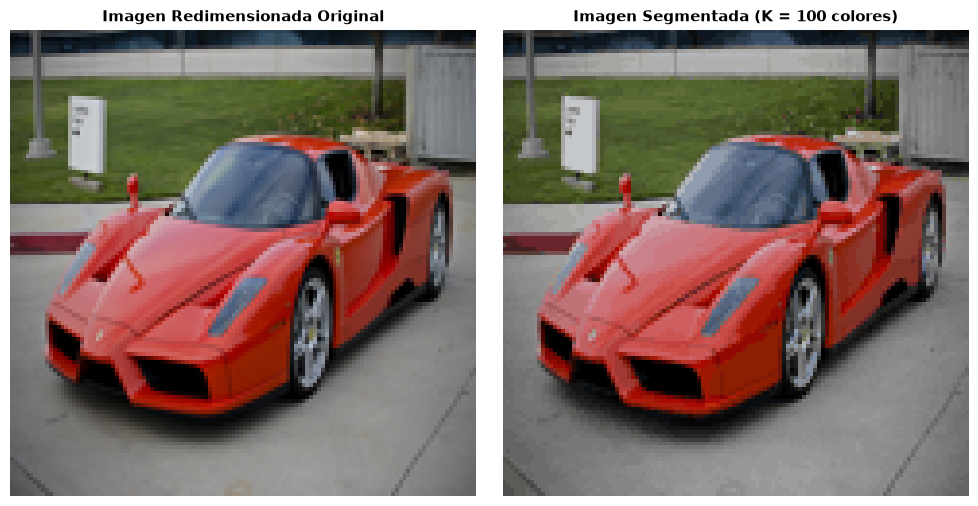

Proceso completo. Mostrando gráficos interactivos...


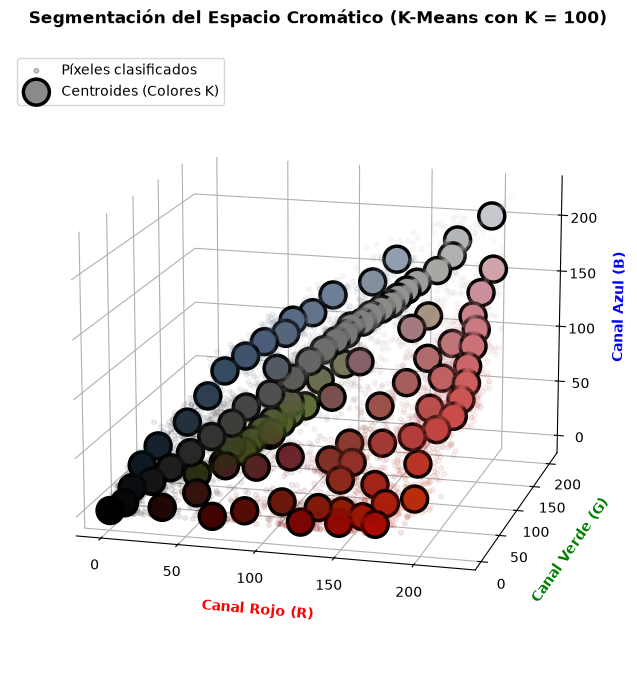

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

# =====================================================================
# 1. CONFIGURACIÓN Y CARGA DE LA IMAGEN
# =====================================================================
# Ruta del archivo original

image_path = '/mnt/c/Users/AZIEL/Pictures/ferrari.jpg'
image = Image.open(image_path).convert('RGB')

# Cargar la imagen y forzarla al formato RGB (evita errores con canales alpha PNG)
image_original = Image.open(image_path).convert('RGB')

# Redimensionar para garantizar un rendimiento fluido del modelo y de la gráfica 3D
# Una resolución de 120x120 genera 14,400 píxeles, muestra excelente detalle y no congela la PC
image_resized = image_original.resize((120, 120)) 
img_array = np.array(image_resized)

# Transformar la estructura 3D (H, W, C) a una matriz 2D (N_píxeles, 3 Canales RGB)
h, w, c = img_array.shape
X = img_array.reshape(-1, 3)

print("--- PROCESAMIENTO DE DATOS ---")
print(f"Dimensiones de la imagen para el modelo: {h}x{w} píxeles.")
print(f"Estructura de la matriz X (Píxeles, Canales RGB): {X.shape}\n")

# =====================================================================
# 2. ENTRENAMIENTO DEL MODELO K-MEANS
# =====================================================================
print("Entrenando el modelo K-Means...")
n_colors = 100  # Número de clusters (K): cuántos colores principales extraer
kmeans = KMeans(n_clusters=n_colors, random_state=42, n_init=10)
kmeans.fit(X)

# Extraer etiquetas asignadas a cada píxel y las coordenadas de los centroides
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

print(f"Centroides RGB encontrados (Valores 0-255):\n{centroids}\n")

# =====================================================================
# 3. RECONSTRUCCIÓN DE LA IMAGEN SEGMENTADA
# =====================================================================
# Reemplazar el color original de cada píxel por el de su centroide asignado
X_compressed = centroids[labels]

# Regresar la matriz 2D a la estructura de imagen original (H, W, C)
# Convertimos a 'uint8' porque los centroides calculados por KMeans son flotantes
img_compressed = X_compressed.reshape(h, w, c).astype('uint8')

# =====================================================================
# 4. VISUALIZACIÓN EN ENTORNO GRÁFICO (MATPLOTLIB)
# =====================================================================
print("Generando interfaz de gráficas...")

# --- Ventana 1: Imagen Original vs Imagen Segmentada ---
fig_imgs, (ax_orig, ax_seg) = plt.subplots(1, 2, figsize=(10, 5), num="Comparativa de Imágenes")

# Subplot Izquierdo: Original
ax_orig.imshow(img_array)
ax_orig.axis('off')
ax_orig.set_title("Imagen Redimensionada Original", fontsize=11, fontweight='bold')

# Subplot Derecho: Comprimida con K-Means
ax_seg.imshow(img_compressed)
ax_seg.axis('off')
ax_seg.set_title(f"Imagen Segmentada (K = {n_colors} colores)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show(block=False)  # Muestra la ventana sin bloquear el hilo de ejecución

# --- Ventana 2: Espacio Tridimensional de Clusters RGB ---
fig_3d = plt.figure(num="Espacio 3D - Clusters K-Means", figsize=(10, 8), facecolor='white')
ax_3d = fig_3d.add_subplot(projection='3d')

# Mapear los colores de fondo para los puntos de la nube (normalizado a escala 0.0 - 1.0)
colors_mapped = X_compressed / 255.0

# Dibujar la nube de píxeles agrupados por color de su cluster
ax_3d.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors_mapped, s=12, alpha=0.3, label='Píxeles clasificados')

# Dibujar los centroides (Masivos, con borde negro para máxima visibilidad en clase)
centroids_normalized = centroids / 255.0
ax_3d.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], 
              c=centroids_normalized, s=350, marker='o', edgecolors='black', 
              linewidths=2.5, depthshade=False, label='Centroides (Colores K)')

# Configuración estética del cubo (Estilo limpio sin paneles grises)
ax_3d.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax_3d.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax_3d.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax_3d.set_facecolor('white')

# Etiquetas de los ejes y título
ax_3d.set_xlabel('Canal Rojo (R)', color='red', fontweight='bold', labelpad=10)
ax_3d.set_ylabel('Canal Verde (G)', color='green', fontweight='bold', labelpad=10)
ax_3d.set_zlabel('Canal Azul (B)', color='blue', fontweight='bold', labelpad=10)
ax_3d.set_title(f'Segmentación del Espacio Cromático (K-Means con K = {n_colors})', pad=20, fontsize=12, fontweight='bold')

# Ajustar ángulo de visión inicial de la nube de puntos
ax_3d.view_init(elev=15, azim=-75)
ax_3d.legend(loc='upper left')

# =====================================================================
# 5. BLOQUEO FINAL Y RENDERIZADO
# =====================================================================
print("Proceso completo. Mostrando gráficos interactivos...")
plt.show(block=True)  # Mantiene ambas ventanas abiertas de manera interactiva
